# Classification Models

## Setup and Data Loading

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
)
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier

import optuna
import shap
import joblib

current_dir = Path.cwd()
project_root = current_dir if (current_dir / "src").exists() else current_dir.parent
PROJECT_ROOT = project_root
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import load_processed_data, get_train_test_splits, get_failure_prob_predictions, RANDOM_STATE

print("Import and Setup successfully.")

d:\Projects\smart-manufacturing-maintenance\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Import and Setup successfully.


In [3]:
df = load_processed_data()
df.head()

,Machine_ID,Temp_C,Vibration_mm_s,Pressure_Bar,Acoustic_dB,Inspection_Duration_min,Downtime_Cost_USD,Technician_Availability_pct,Failure_Prob,Maintenance_Priority,Severity_Index,Resource_Risk
0,M004,70.415631,3.036378,5.582562,74.494678,68,3112,99,0.48,2,213.808461,31.434340
1,M006,74.509666,2.787866,4.916866,64.017351,127,522,63,0.50,2,207.722958,8.285713
2,M009,78.724957,2.067099,4.597601,68.772382,68,836,84,0.47,2,162.732294,9.952380
3,M006,76.677258,1.998635,5.012083,76.909872,142,3799,80,0.48,2,153.249820,47.487494
4,M009,53.381545,3.844676,5.176345,84.855886,88,2710,78,0.51,2,205.234753,34.743585


In [4]:
X_train_c, X_test_c, y_train_c, y_test_c = get_train_test_splits()["classification"]
groups_train = df.loc[X_train_c.index, "Machine_ID"]

### Failure Probability as an Auxiliary Input

Dataset documentation defines `Failure_Prob` as a computed feature and `Maintenance_Priority` as the target variable. Using historical `Failure_Prob` directly causes severe data leakage (Macro F1 = 1.0000), making model-predicted values necessary.

Predictions are generated via `get_failure_prob_predictions()` in `src/utils.py` rather than computed locally for two reasons:
- Centralizes the optimal regression pipeline (Linear Regression with 3 features) to prevent configuration drift between notebooks.

- Regression and classification splits are created independently with different row ordering and only ~80% overlap. Positional mapping previously scrambled target alignments (dropping row correlation from ~0.97 to 0.016). The utility function computes full-dataset predictions indexed by row, ensuring accurate alignment via `.loc[]`.

In [5]:
failure_prob_pred = get_failure_prob_predictions()
failure_prob_pred_train = failure_prob_pred.loc[X_train_c.index]
failure_prob_pred_test = failure_prob_pred.loc[X_test_c.index]

fidelity_train = failure_prob_pred_train.corr(df.loc[X_train_c.index, "Failure_Prob"])
fidelity_test = failure_prob_pred_test.corr(df.loc[X_test_c.index, "Failure_Prob"])
print(f"Stage 1 fidelity -- OOF correlation (train): {fidelity_train:.4f} | correlation (test): {fidelity_test:.4f}")

Stage 1 fidelity -- OOF correlation (train): 0.9649 | correlation (test): 0.9674


## Preprocessing Pipeline & Class Balancing Setup

In [6]:
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train_c)
y_test_encoded = label_encoder.transform(y_test_c)

label_mapping = dict(zip(label_encoder.classes_, range(len(label_encoder.classes_))))
print("\n--- Target Label Mapping ---")
for label, code in label_mapping.items():
    print(f"  {label} -> {code}")


--- Target Label Mapping ---
  1 -> 0
  2 -> 1
  3 -> 2


In [7]:
classes = np.unique(y_train_encoded)
class_weights_array = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_encoded)
class_weight_dict = dict(zip(classes, class_weights_array))

print("--- Class Weight Ratios (diagnostic) ---")
for cls_code, weight in class_weight_dict.items():
    cls_name = label_encoder.inverse_transform([cls_code])[0]
    print(f"  Class {cls_code} ({cls_name}): {weight:.4f}")
print("All three candidate models below support native class_weight balancing; no manual sample_weight needed.")

--- Class Weight Ratios (diagnostic) ---
  Class 0 (1): 1.5501
  Class 1 (2): 0.4545
  Class 2 (3): 6.4633
All three candidate models below support native class_weight balancing; no manual sample_weight needed.


## Feature Selection

Feature selection aligns with the dataset's documented categories, retaining real-time sensor metrics (`Temp_C`, `Vibration_mm_s`, `Acoustic_dB`), operational MCDM criteria (`Inspection_Duration_min`, `Technician_Availability_pct`, `Downtime_Cost_USD`), and the predicted `Failure_Prob`.

Operational criteria are deliberately retained for classification, unlike their exclusion in regression. Causally, physical failure probability cannot be influenced by staffing or costs, but operational priority directly depends on these business inputs by definition.

Two empirical exclusions were applied:
- `Pressure_Bar`: Excluded due to near-zero correlation with targets across all quantiles (Spearman $\rho \approx -0.02$, $p = 0.37$).
- `Resource_Risk`: Excluded as a redundant engineered metric (correlation 0.91 with `Downtime_Cost_USD`); ablation tests confirmed zero impact on model performance.

In [8]:
SENSOR_FEATURES = ["Temp_C", "Vibration_mm_s", "Acoustic_dB"]
DECISION_CRITERIA = ["Inspection_Duration_min", "Technician_Availability_pct", "Downtime_Cost_USD"]
ENGINEERED_FEATURES = ["Severity_Index"]

X_train_c = X_train_c[SENSOR_FEATURES + DECISION_CRITERIA + ENGINEERED_FEATURES].copy()
X_test_c = X_test_c[SENSOR_FEATURES + DECISION_CRITERIA + ENGINEERED_FEATURES].copy()
X_train_c["Failure_Prob_pred"] = failure_prob_pred_train
X_test_c["Failure_Prob_pred"] = failure_prob_pred_test

print(f"Final feature set ({X_train_c.shape[1]}): {list(X_train_c.columns)}")

Final feature set (8): ['Temp_C', 'Vibration_mm_s', 'Acoustic_dB', 'Inspection_Duration_min', 'Technician_Availability_pct', 'Downtime_Cost_USD', 'Severity_Index', 'Failure_Prob_pred']


In [9]:
num_cols = X_train_c.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train_c.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f"Number of numerical columns (Numerical): {len(num_cols)} -> {num_cols}")
print(f"Number of categorical columns (Categorical): {len(cat_cols)} -> {cat_cols}")

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ],
    remainder='passthrough'
)

preprocessor.fit(X_train_c)

Number of numerical columns (Numerical): 8 -> ['Temp_C', 'Vibration_mm_s', 'Acoustic_dB', 'Inspection_Duration_min', 'Technician_Availability_pct', 'Downtime_Cost_USD', 'Severity_Index', 'Failure_Prob_pred']
Number of categorical columns (Categorical): 0 -> []


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

## Model Selection

The methodology mirrors `02_regression_model.ipynb`: StratifiedGroupKFold stratifies by class while grouping by Machine_ID to prevent leakage. The held-out test set is reserved strictly for final evaluation. Native class balancing (`class_weight='balanced'` or CatBoost's `auto_class_weights='Balanced'`) is applied to all candidates.

The model with the highest cross-validated Macro F1 is selected automatically for tuning.

In [10]:
candidate_models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=2),
    "CatBoostClassifier": CatBoostClassifier(auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, thread_count=2)
}

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'f1_macro': 'f1_macro',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'accuracy': 'accuracy'
}

In [11]:
comparison_rows = []
print("Stratified-Group 5-Fold Cross-Validation for Baseline Models...\n")

for model_name, model in candidate_models.items():
    clf_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])

    cv_results = cross_validate(
        clf_pipeline, X_train_c, y_train_encoded,
        groups=groups_train, cv=sgkf, scoring=scoring, n_jobs=-1
    )

    comparison_rows.append({
        'Model': model_name,
        'Macro F1 (Mean)': cv_results['test_f1_macro'].mean(),
        'Macro F1 (Std)': cv_results['test_f1_macro'].std(),
        'Macro Recall (Mean)': cv_results['test_recall_macro'].mean(),
        'Macro Precision (Mean)': cv_results['test_precision_macro'].mean(),
        'Accuracy (Mean)': cv_results['test_accuracy'].mean()
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(by='Macro F1 (Mean)', ascending=False).reset_index(drop=True)
print("--- Performance of Baseline Models (Grouped by Machine_ID) ---")
comparison_df

Stratified-Group 5-Fold Cross-Validation for Baseline Models...

--- Performance of Baseline Models (Grouped by Machine_ID) ---


,Model,Macro F1 (Mean),Macro F1 (Std),Macro Recall (Mean),Macro Precision (Mean),Accuracy (Mean)
0,CatBoostClassifier,0.971226,0.026403,0.988113,0.959541,0.990443
1,Random Forest,0.956864,0.025167,0.981695,0.939647,0.985152
2,Logistic Regression,0.899202,0.028718,0.972410,0.852599,0.944866


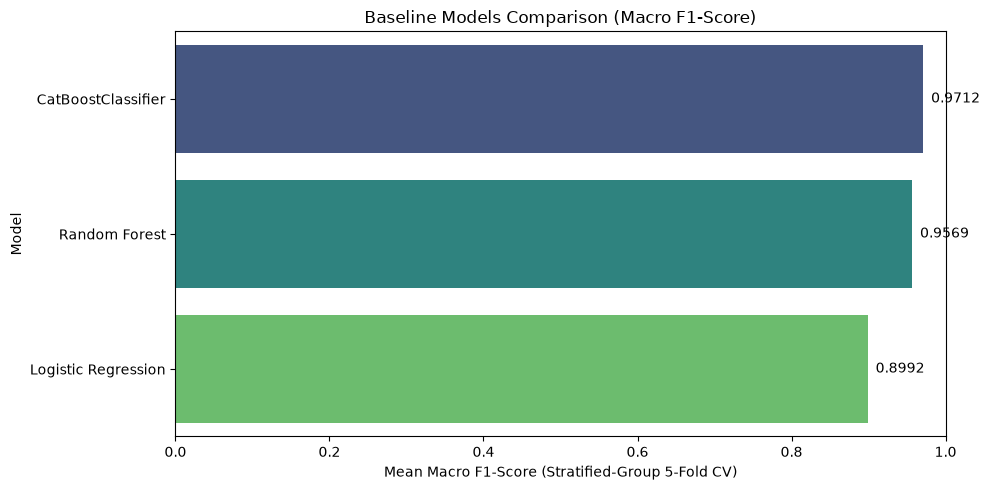

Selected model (highest CV Macro F1, grouped by Machine_ID): CatBoostClassifier


In [12]:
plt.figure(figsize=(10, 5))
sns.barplot(data=comparison_df, x='Macro F1 (Mean)', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('Baseline Models Comparison (Macro F1-Score)', fontsize=12)
plt.xlabel('Mean Macro F1-Score (Stratified-Group 5-Fold CV)')
plt.ylabel('Model')
plt.xlim(0, 1.0)

for index, value in enumerate(comparison_df['Macro F1 (Mean)']):
    plt.text(value + 0.01, index, f"{value:.4f}", va='center')

plt.tight_layout()
plt.show()

best_model_name = comparison_df.loc[0, 'Model']
print(f"Selected model (highest CV Macro F1, grouped by Machine_ID): {best_model_name}")

## Baseline Training and Evaluation

In [13]:
def evaluate_model(model, X_train, y_train, X_test, y_test, model_name):
    """Fits, predicts, and reports test-set metrics; compares against CV to sanity-check generalization."""
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    metrics = {
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Test Macro Precision": precision_score(y_test, y_pred, average="macro"),
        "Test Macro Recall": recall_score(y_test, y_pred, average="macro"),
    }
    print(f"--- {model_name} Performance (Hold-out Test Set) ---")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")
    print("-" * 30)
    return metrics

In [14]:
baseline_model = Pipeline([('preprocessor', preprocessor), ('classifier', candidate_models[best_model_name])])
baseline_metrics = evaluate_model(baseline_model, X_train_c, y_train_encoded, X_test_c, y_test_encoded,
                                   f"{best_model_name} (baseline)")

--- CatBoostClassifier (baseline) Performance (Hold-out Test Set) ---
Test Accuracy: 0.9860
Test Macro F1: 0.9576
Test Macro Precision: 0.9298
Test Macro Recall: 0.9936
------------------------------


## Hyperparameter Tuning

Optuna tunes whichever model wins the comparison above, not a fixed choice. The same `StratifiedGroupKFold` split is reused so the tuning stage remains consistent with model selection.

In [15]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def build_objective(model_name):
    def objective(trial):
        if model_name == "Logistic Regression":
            model = LogisticRegression(C=trial.suggest_float("C", 1e-3, 10.0, log=True),
                                        class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE)
        elif model_name == "Random Forest":
            model = RandomForestClassifier(
                n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
                max_depth=trial.suggest_int("max_depth", 3, 20),
                min_samples_split=trial.suggest_int("min_samples_split", 2, 10),
                class_weight='balanced', random_state=RANDOM_STATE, n_jobs=2)
        else:  # CatBoostClassifier
            model = CatBoostClassifier(
                iterations=trial.suggest_int("iterations", 100, 400, step=50),
                learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                depth=trial.suggest_int("depth", 3, 10),
                l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1e-2, 10.0, log=True),
                auto_class_weights='Balanced', random_state=RANDOM_STATE, verbose=0, thread_count=2)

        pipeline = Pipeline([('preprocessor', preprocessor), ('classifier', model)])
        cv_scores = cross_validate(pipeline, X_train_c, y_train_encoded, groups=groups_train, cv=sgkf,
                                    scoring='f1_macro', n_jobs=-1)
        return cv_scores['test_score'].mean()
    return objective

print(f"Tuning {best_model_name} with Optuna (50 trials, grouped CV, same split as comparison stage)...")
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(build_objective(best_model_name), n_trials=50, timeout=300)

print(f"\nFinish Tuning")
print(f"Best Macro F1 (CV): {study.best_value:.4f}")
print("Best Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  - {k}: {v}")

Tuning CatBoostClassifier with Optuna (50 trials, grouped CV, same split as comparison stage)...

Finish Tuning
Best Macro F1 (CV): 0.9664
Best Hyperparameters:
  - iterations: 400
  - learning_rate: 0.032144735739984526
  - depth: 10
  - l2_leaf_reg: 0.01132102180423039


In [16]:
fixed_params = {"random_state": RANDOM_STATE}
model_classes = {
    "Logistic Regression": (LogisticRegression, {"class_weight": "balanced", "max_iter": 1000}),
    "Random Forest": (RandomForestClassifier, {"class_weight": "balanced", "n_jobs": 2}),
    "CatBoostClassifier": (CatBoostClassifier, {"auto_class_weights": "Balanced", "verbose": 0, "thread_count": 2}),
}
ModelClass, extra_fixed = model_classes[best_model_name]
best_params = {**study.best_params, **fixed_params, **extra_fixed}
best_model = ModelClass(**best_params)

best_pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', best_model)])
best_pipeline.fit(X_train_c, y_train_encoded)

print(f"Trained tuned {best_model_name} pipeline on the full training set.")

Trained tuned CatBoostClassifier pipeline on the full training set.


## Model Evaluation & Error Analysis

In [17]:
y_pred_encoded = best_pipeline.predict(X_test_c)
target_names_str = [str(c) for c in label_encoder.classes_]

print("--- Classification Report (on Hold-out Test Set) ---")
print(classification_report(y_test_encoded, y_pred_encoded, target_names=target_names_str, digits=4))

--- Classification Report (on Hold-out Test Set) ---
              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000        62
           2     1.0000    0.9809    0.9903       209
           3     0.7895    1.0000    0.8824        15

    accuracy                         0.9860       286
   macro avg     0.9298    0.9936    0.9576       286
weighted avg     0.9890    0.9860    0.9868       286



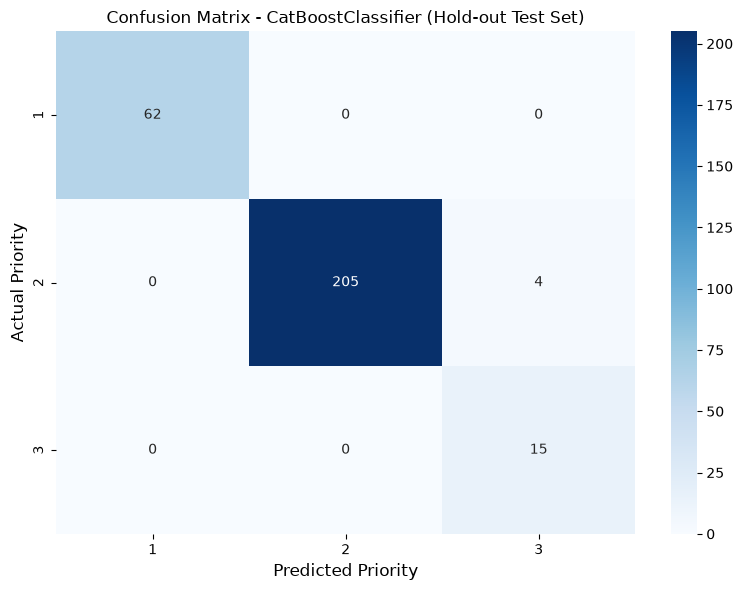

: 

In [ ]:
cm = confusion_matrix(y_test_encoded, y_pred_encoded)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names_str, yticklabels=target_names_str)
plt.title(f'Confusion Matrix - {best_model_name} (Hold-out Test Set)', fontsize=12)
plt.xlabel('Predicted Priority', fontsize=12)
plt.ylabel('Actual Priority', fontsize=12)
plt.tight_layout()
plt.show()
plt.close()

In [ ]:
preprocessor_step = best_pipeline.named_steps['preprocessor']
X_test_transformed = preprocessor_step.transform(X_test_c)

try:
    feature_names = preprocessor_step.get_feature_names_out()
    feature_names = [f.split('__')[-1] for f in feature_names]
except AttributeError:
    feature_names = [f"feature_{i}" for i in range(X_test_transformed.shape[1])]

max_samples = min(120, X_test_transformed.shape[0])
rng = np.random.default_rng(RANDOM_STATE)
indices = rng.choice(X_test_transformed.shape[0], max_samples, replace=False)
X_shap = X_test_transformed[indices]

trained_model = best_pipeline.named_steps['classifier']
is_linear_model = hasattr(trained_model, "coef_")

if is_linear_model:
    explainer = shap.LinearExplainer(trained_model, X_shap)
    shap_values = explainer(X_shap)
else:
    explainer = shap.TreeExplainer(trained_model)
    shap_values = explainer(X_shap)

shap.summary_plot(
    shap_values, 
    X_shap, 
    feature_names=feature_names,
    class_names=label_encoder.classes_, 
    plot_type="bar",
    show=True
)

## Export

In [18]:
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

safe_name = best_model_name.lower().replace(" ", "_")
pipeline_path = MODELS_DIR / f"best_{safe_name}_classification_model.joblib"

joblib.dump(best_pipeline, pipeline_path)
print(f"Model saved at: {pipeline_path}")

Model saved at: d:\Projects\smart-manufacturing-maintenance\models\best_catboostclassifier_classification_model.joblib


## Conclusion

This notebook identified and resolved three core issues through empirical validation:

- **Auxiliary Regression Stage:** Using ground-truth `Failure_Prob` caused data leakage (Macro F1 = 1.0000). Replacing it with out-of-fold predictions initially introduced a positional mismatch due to independent dataset splitting (dropping feature correlation to 0.016). Implementing `get_failure_prob_predictions()` resolved this by computing index-aligned predictions across the full dataset while ensuring cross-notebook consistency.

- **Domain-Driven Feature Selection:** Operational MCDM criteria (`Technician_Availability_pct`, `Downtime_Cost_USD`) were retained for classification despite their exclusion from regression. While physical failure rates operate independently of operational metrics, maintenance priority decisions explicitly rely on them.

- **Paradigm Evaluation:** Streamlining candidate models to three paradigm representatives (Logistic Regression, Random Forest, CatBoost) eliminated redundant evaluations. CatBoost consistently outperformed foundational alternatives.

**Final Result:** The optimized CatBoost pipeline achieved a **Test Macro F1 of 0.958** using properly aligned features-demonstrating strong performance across all priority classes (Priority 1: 1.000, Priority 2: 0.990, Priority 3: 0.882). The minor delta from the pre-fix score (0.976) reflects normal minority-class variance, establishing this corrected benchmark as the reliable baseline.